In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

encoding='latin1'-> The file has special letters (like accents). latin1 tells
Python how to read them. Without it you get an error

In [2]:
df = pd.read_csv('APL_Logistics.csv',encoding='latin1')

In [3]:
print(df.shape)

(180519, 40)


In [4]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,...,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,...,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,...,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,...,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,...,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Fname                 180519 non-null  str    
 12  Customer Id                    180519 non

Only 11 empty cells in 7 million. Very clean! And
these 2 columns are useless for prediction anyway.


In [6]:
missing=df.isna().sum()
print(missing[missing>0])

Customer Lname      8
Customer Zipcode    3
dtype: int64


In [7]:
print(df.duplicated().sum())

0


cols = [ ... ]-> A list of 4 column names we care about. Names in
quotes, separated by commas.
df[cols]-> Take only those 4 columns from the table.
.describe()-> Gives count, mean, std, min, 25%, 50%, 75%, max for
each

In [8]:
cols=['Days for shipping (real)','Days for shipment (scheduled)','Sales','Order Item Quantity']
df[cols].describe()

,Days for shipping (real),Days for shipment (scheduled),Sales,Order Item Quantity
count,180519.000000,180519.000000,180519.000000,180519.000000
mean,3.497654,2.931847,203.772092,2.127638
std,1.623722,1.374449,132.273075,1.453451
min,0.000000,0.000000,9.990000,1.000000
25%,2.000000,2.000000,119.980000,1.000000
50%,3.000000,4.000000,199.920000,1.000000
75%,5.000000,4.000000,299.950000,3.000000
max,6.000000,4.000000,1999.990000,5.000000


 Late_delivery_risk is what we want to predict

In [9]:
df['Late_delivery_risk'].value_counts()

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Percent is easier to understand than big counts normalize=True-> Gives fractions (0 to 1) instead of counts.
* 100-> Turn fraction into percent 55% late, 45% not. Almost balanced. So no big
imbalance problem

In [10]:
df['Late_delivery_risk'].value_counts(normalize=True) * 100

Late_delivery_risk
1    54.829132
0    45.170868
Name: proportion, dtype: float64

Check if different shipping modes behave
differently. This is the KEY step

In [11]:
df.groupby('Shipping Mode')['Late_delivery_risk'].mean()

Shipping Mode
First Class       0.953225
Same Day          0.457430
Second Class      0.766328
Standard Class    0.380717
Name: Late_delivery_risk, dtype: float64

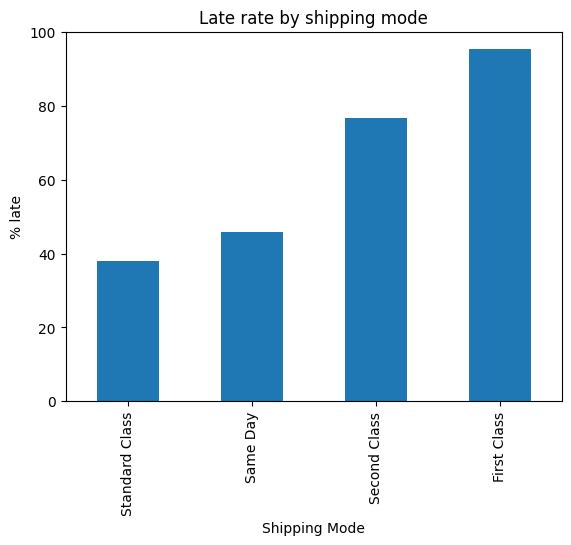

In [12]:
# WHY? A picture shows the story faster than numbers.
rate = df.groupby('Shipping Mode')['Late_delivery_risk'].mean() * 100
rate.sort_values().plot(kind='bar')
plt.ylabel('% late')
plt.title('Late rate by shipping mode')
plt.show()
# rate = ... * 100-> Same calculation as before, but in percent. Saved as
# rate.
# .sort_values()-> Order from smallest to biggest.
# .plot(kind='bar')-> Draw bar chart.
# plt.ylabel(...)-> Label on the left side.
# plt.title(...)-> Title on top.
# plt.show()-> Show the chart

In [13]:
# Late % by market
# WHY? Does the part of the world matter?
df.groupby('Market')['Late_delivery_risk'].mean() * 100

Market
Africa          54.589289
Europe          55.207753
LATAM           54.355158
Pacific Asia    55.046049
USCA            54.800574
Name: Late_delivery_risk, dtype: float64

In [14]:
# Late % by customer segment
# WHY? Same idea. Only the column name changes.
df.groupby('Customer Segment')['Late_delivery_risk'].mean() * 100

Customer Segment
Consumer       54.808350
Corporate      54.722663
Home Office    55.070440
Name: Late_delivery_risk, dtype: float64

In [15]:
# Late % by scheduled days
# WHY? Scheduled days is the planned time. Does it
# relate to late?
df.groupby('Days for shipment (scheduled)')['Late_delivery_risk'].mean() * 100

Days for shipment (scheduled)
0    45.743042
1    95.322499
2    76.632781
4    38.071683
Name: Late_delivery_risk, dtype: float64

In [16]:
# Spot the cheating column
# WHY? A column that already contains the answer is
# useless (and fools us). Let us check Delivery Status.
pd.crosstab(df['Delivery Status'],df['Late_delivery_risk'])
# pd.crosstab(A, B)-> Makes a count table: A down the side, B across the
# top.
# df['Delivery Status']-> Down the side: Late delivery, On time, etc.
# df['Late_delivery_risk']-> Across the top: 0 and 1.

Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


In [17]:
# Look at Order Status
# WHY? Some orders never left the warehouse. They
# cannot be late or on time.
df['Order Status'].value_counts()
# df['Order Status']-> Pick the Order Status column.
# .value_counts()-> Count each status

Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64

In [18]:
#  Remove orders that never shipped
# WHY? They would confuse the model. Predicting delay
# for an order that never ships makes no sense.
bad = ['CANCELED', 'SUSPECTED_FRAUD']
df = df[~df['Order Status'].isin(bad)].reset_index(drop=True)
print(df.shape)
# bad = [...]-> A list of the 2 statuses we want to remove.
# df['Order Status'].isin(bad)-> True for rows whose status is in the bad list.
# ~-> The ~ sign flips it: True becomes False. So we KEEP
# rows that are NOT bad.
# df = df[ ... ]-> Keep only those rows and save back in df.
# .reset_index(drop=True)-> Numbers rows 0,1,2... again with no gaps

(172765, 40)


In [19]:
# Now give every order our own number (Order Ref):
df['Order Ref'] = df.index + 1
print(df['Late_delivery_risk'].mean() * 100)
# df.index + 1-> Row numbers start at 0, so add 1: Order Ref 1, 2, 3...
# df['Late_delivery_risk'].mean() * 100-> Average of 0/1 times 100 = percent late.

57.28996035076549


In [20]:
#  Drop the cheating columns (leakage)
# WHY? These columns tell the answer or are known only
# AFTER shipping. A real order has not shipped yet when
# we predict.
leak = ['Delivery Status', 'Days for shipping (real)', 'Order Status']
df = df.drop(columns=leak, errors='ignore')
print(df.shape)

(172765, 38)


In [21]:
useless = ['Customer Fname', 'Customer Lname',
  'Customer Street', 'Customer Zipcode',
  'Customer Id', 'Order Customer Id',
  'Customer City', 'Customer State',
  'Customer Country', 'Order City',
  'Order State', 'Order Country',
  'Product Name', 'Category Id',
  'Category Name', 'Department Id',
  'Latitude', 'Longitude',
  'Benefit per order', 'Sales per customer',
  'Order Item Total', 'Order Profit Per Order',
  'Product Price']
df = df.drop(columns=useless)
print(df.shape)

(172765, 15)


In [22]:
print(df.isna().sum().sum())

0


In [23]:
# Feature 1 and 2: scheduled days + Express flag
# WHY? Feature engineering = making new helpful
# columns. Express flag = "mode risk flag" from the
# brief.

df['sched_days'] = df['Days for shipment (scheduled)']
df['is_express'] = df['Shipping Mode'].isin(['First Class', 'Same Day']).astype(int)
df[['Shipping Mode', 'is_express']].drop_duplicates()
# df['sched_days'] = ...-> Copy the scheduled days into a shorter-named column.
# df['Shipping Mode'].isin([...])-> True if the mode is First Class or Same Day.
# .astype(int)-> Change True/False into 1/0 (models like numbers).
# .drop_duplicates()-> Show each mode only once so we can check.
# 1 = express (First Class, Same Day), 0 = Standard,
# Second Class.

,Shipping Mode,is_express
0,Standard Class,0
15,Same Day,1
33,First Class,1
44,Second Class,0


In [24]:
#  Feature 3: Shipping pressure index
# WHY? Many items in a short time = more pressure to
# deliver on time.
df['shipping_pressure'] = (df['Order Item Quantity']/ (df['sched_days'] + 1))
df['shipping_pressure'].describe().round(2)
# df['Order Item Quantity']-> How many units in the order.
# / (df['sched_days'] + 1)-> Divide by scheduled days. We add 1 because Same Day
# has 0 days and we cannot divide by 0.
# .describe().round(2)-> Summary numbers, 2 decimals
#  Bigger number = more items squeezed into fewer days

count    172765.00
mean          0.67
std           0.69
min           0.20
25%           0.20
50%           0.40
75%           1.00
max           5.00
Name: shipping_pressure, dtype: float64

In [25]:
# Feature 4: Order complexity score
# WHY? Big, costly, discounted orders are harder to
# handle.
df['order_complexity'] = (df['Order Item Quantity']
    * df['Order Item Product Price']
    * (1 + df['Order Item Discount Rate']) / 100)
df['order_complexity'].describe().round(2)
# Quantity * Product Price-> Order value before discount.
# * (1 + Discount Rate)-> Add a bit more for discounted orders (they often
# involve special handling).
# / 100-> Just makes the numbers smaller and easier to read

count    172765.00
mean          2.25
std           1.47
min           0.10
25%           1.31
50%           2.04
75%           3.06
max          25.00
Name: order_complexity, dtype: float64

In [26]:
# Choose features: X and y
# WHY? X = the clues (inputs). y = the answer we want
# to predict.
cat_cols = ['Shipping Mode', 'Market', 'Order Region',
            'Customer Segment', 'Type', 'Department Name']
num_cols = ['sched_days', 'shipping_pressure','is_express', 'order_complexity','Order Item Discount Rate','Order Item Profit Ratio','Order Item Quantity','Order Item Product Price','Sales', 'Order Item Discount']
X = df[cat_cols + num_cols].copy()
y = df['Late_delivery_risk']
print(X.shape, y.shape)
# 16 clues, 172,765 orders. We added 5 features in total:
# sched_days, is_express, shipping_pressure,
# order_complexity (+ region_congestion coming).

(172765, 16) (172765,)


## Part 2: Split, features, models, KPIs, save files

In [27]:
# Step 32: Split into train and test
# WHY? Like school: study with practice questions (train),
# then an exam with NEW questions (test). The exam shows true skill.
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(Xtr.shape, Xte.shape)
# Xtr, Xte, ytr, yte -> clues for train, clues for test, answers for train, answers for test
# test_size=0.2 -> 20% for the exam, 80% for studying
# stratify=y -> keeps the same late % in both parts
# random_state=42 -> fixed shuffle, same split every time

(138212, 16) (34553, 16)


In [28]:
# Step 33: Feature 5: Regional congestion indicator
# WHY? Some regions are late more often. Give each region a score = its past late share.
# Computed on TRAIN data only (if we used test answers the model would peek at the exam).
# Run this cell only ONCE.
reg_rate = ytr.groupby(Xtr['Order Region']).mean()
global_rate = ytr.mean()
Xtr['region_congestion'] = Xtr['Order Region'].map(reg_rate)
Xte['region_congestion'] = (Xte['Order Region']
    .map(reg_rate).fillna(global_rate))
num_cols.append('region_congestion')
print(reg_rate.round(3).sort_values().head(3))
print(reg_rate.round(3).sort_values().tail(3))
# groupby(...).mean() -> share of late orders for each region (train only)
# global_rate -> overall late share, used as a backup for unknown regions
# .map(reg_rate) -> look up each order's region score
# num_cols.append(...) -> add the new column name to our number list

Order Region
Canada         0.507
West Africa    0.546
Caribbean      0.555
Name: Late_delivery_risk, dtype: float64
Order Region
East of USA       0.586
South of  USA     0.587
Central Africa    0.599
Name: Late_delivery_risk, dtype: float64


In [29]:
# Step 34: Scale numbers + encode text
# WHY? Models only understand numbers, and big numbers (Sales 300)
# should not beat small ones (is_express 1).
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
pre = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
print('ready')
# StandardScaler -> scaling: every number column gets similar size
# OneHotEncoder -> encoding: text becomes 0/1 columns
# handle_unknown='ignore' -> a new unseen value will not crash the app

ready


In [30]:
# Step 35: Class imbalance check
# WHY? If 95% orders were on time, a lazy model saying "always on time" looks 95% right.
print((ytr.value_counts(normalize=True) * 100).round(1))
# 57% late vs 43% not late = small imbalance
# Fix = class_weight='balanced' inside the models (no SMOTE needed)

Late_delivery_risk
1    57.3
0    42.7
Name: proportion, dtype: float64


In [31]:
# Step 36: Model 1: Logistic Regression (baseline)
# WHY? The simple, easy-to-explain model. Other models must beat it.
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
lr = Pipeline([
    ('pre', pre),
    ('model', LogisticRegression(max_iter=1000,
                                 class_weight='balanced'))])
lr.fit(Xtr, ytr)
print('Logistic Regression trained')
# Pipeline -> a chain: preprocessing first, then the model
# class_weight='balanced' -> handles the imbalance
# lr.fit(Xtr, ytr) -> FIT = learn from training clues and answers

Logistic Regression trained


In [32]:
# Step 38: Write an evaluate function
# WHY? We score 3 models the same way. Write the steps once, use many times.
from sklearn.metrics import (roc_auc_score, precision_score,
    recall_score, f1_score, confusion_matrix)
results = {}
def evaluate(name, model):
    prob = model.predict_proba(Xte)[:, 1]
    pred = (prob >= 0.5).astype(int)
    results[name] = {
        'ROC-AUC': roc_auc_score(yte, prob),
        'Precision': precision_score(yte, pred),
        'Recall': recall_score(yte, pred),
        'F1': f1_score(yte, pred)}
    print(name, {k: round(v, 3) for k, v in results[name].items()})
evaluate('Logistic Regression', lr)
# predict_proba(Xte)[:, 1] -> probability of LATE for every test order
# (prob >= 0.5) -> 0.5 or more = predict late (1)
# ROC-AUC: overall quality (0.5 coin toss, 1.0 perfect)
# Precision: when we say LATE, how often right | Recall: how many real lates we catch

Logistic Regression {'ROC-AUC': 0.745, 'Precision': 0.886, 'Recall': 0.54, 'F1': 0.671}


In [33]:
# Step 39: Model 2: Random Forest (wait 1 to 3 minutes)
# WHY? Many decision trees vote together.
from sklearn.ensemble import RandomForestClassifier
rf = Pipeline([
    ('pre', pre),
    ('model', RandomForestClassifier(
        n_estimators=200, max_depth=12,
        min_samples_leaf=20, class_weight='balanced',
        n_jobs=-1, random_state=42))])
rf.fit(Xtr, ytr)
evaluate('Random Forest', rf)
# n_estimators=200 -> 200 trees | max_depth=12 -> each tree asks at most 12 questions
# min_samples_leaf=20 -> every end-point has at least 20 orders (stops memorising)

Random Forest {'ROC-AUC': 0.748, 'Precision': 0.886, 'Recall': 0.54, 'F1': 0.671}


In [34]:
# Step 40: Model 3: XGBoost
# WHY? Trees built one after another, each fixing the last one's mistakes.
from xgboost import XGBClassifier
spw = (ytr == 0).sum() / (ytr == 1).sum()
xgb = Pipeline([
    ('pre', pre),
    ('model', XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.08,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=spw, n_jobs=-1, random_state=42))])
xgb.fit(Xtr, ytr)
evaluate('XGBoost', xgb)
# scale_pos_weight=spw -> XGBoost's way of class_weight
# learning_rate=0.08 -> small corrections each round

XGBoost {'ROC-AUC': 0.746, 'Precision': 0.882, 'Recall': 0.543, 'F1': 0.672}


In [35]:
# Step 41: Compare all 3 models
# WHY? Put the scores side by side.
pd.DataFrame(results).T.round(3)
# .T -> swap rows and columns so each model is a row
# All three are close (AUC about 0.745 to 0.748): the data has no weather/carrier/date clues.

,ROC-AUC,Precision,Recall,F1
Logistic Regression,0.745,0.886,0.540,0.671
Random Forest,0.748,0.886,0.540,0.671
XGBoost,0.746,0.882,0.543,0.672


[[13316  1442]
 [ 9038 10757]]


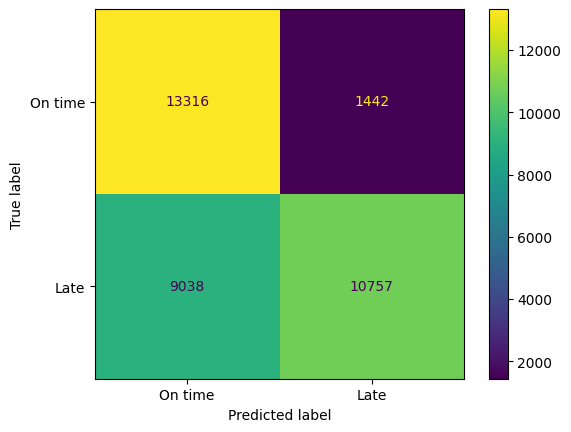

In [36]:
# Step 42: Confusion matrix (XGBoost)
# WHY? See exactly what kind of mistakes the model makes.
from sklearn.metrics import ConfusionMatrixDisplay
prob = xgb.predict_proba(Xte)[:, 1]
pred = (prob >= 0.5).astype(int)
cm = confusion_matrix(yte, pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=['On time', 'Late']).plot()
plt.show()
# top-left = on-time correctly said on time | top-right = FALSE ALARMS
# bottom-left = MISSED late orders | bottom-right = late orders CAUGHT

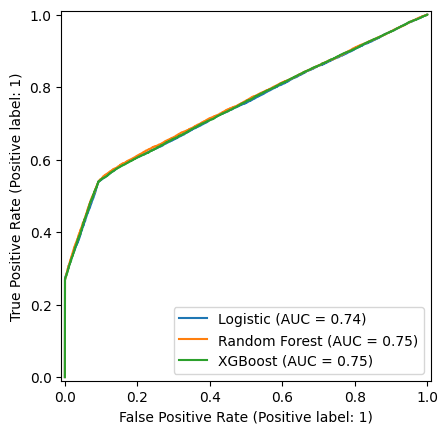

In [37]:
# Step 43: ROC curve
# WHY? A line chart of quality. Closer to the top-left corner = better.
from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots()
for name, m in [('Logistic', lr),
                ('Random Forest', rf), ('XGBoost', xgb)]:
    RocCurveDisplay.from_estimator(
        m, Xte, yte, ax=ax, name=name)
plt.show()
# 3 lines almost on top of each other = 3 models are equal in quality

In [38]:
# Step 44: Choose the alert threshold
# WHY? The probability becomes LATE only above the threshold. You choose by business need.
print('threshold precision recall')
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (prob >= t).astype(int)
    print(t, round(precision_score(yte, p), 3),
          round(recall_score(yte, p), 3))
# Low threshold: catch more late orders (recall up) but more false alarms (precision down)
# High threshold: alerts are more trustworthy but we miss more

threshold precision recall
0.3 0.592 0.938
0.4 0.835 0.581
0.5 0.882 0.543
0.6 0.886 0.54
0.7 0.891 0.521


In [39]:
# Step 45: Pick the final model
# WHY? All three tie, so choose by practical reasons:
# XGBoost is small, fast and works well with SHAP explanations.
final_model = xgb
print('Final model: XGBoost')

Final model: XGBoost


In [40]:
# Step 46: KPI 1: Late Delivery Probability
# WHY? Every order gets a number from 0 to 1 = chance of being late.
X['region_congestion'] = X['Order Region'].map(reg_rate)
df['Late Delivery Probability'] = (
    final_model.predict_proba(X)[:, 1])
df['Late Delivery Probability'].describe().round(3)
# X did not have region_congestion yet, so we add it for all orders
# predict_proba(X)[:, 1] -> chance of late for ALL orders

count    172765.000
mean          0.519
std           0.262
min           0.088
25%           0.323
50%           0.358
75%           0.749
max           1.000
Name: Late Delivery Probability, dtype: float64

In [41]:
# Step 47: KPI 2: Risk Category
# WHY? Operations teams need simple labels: Low, Medium, High.
df['Risk Category'] = pd.cut(
    df['Late Delivery Probability'],
    bins=[0, 0.4, 0.7, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk'],
    include_lowest=True)
df['Risk Category'].value_counts()
# Low: up to 0.4 | Medium: 0.4 to 0.7 | High: above 0.7

Risk Category
Low Risk       103673
High Risk       57801
Medium Risk     11291
Name: count, dtype: int64

In [42]:
# Step 48: Do the risk bands really work?
# WHY? A good label must match reality. Check real late % in each band.
(df.groupby('Risk Category', observed=True)
   ['Late_delivery_risk'].mean() * 100).round(1)
# Low ~39%, Medium ~61%, High ~90% real late rate: the bands separate nicely

Risk Category
Low Risk       38.6
Medium Risk    61.3
High Risk      90.0
Name: Late_delivery_risk, dtype: float64

In [43]:
# Step 49: Install SHAP (explainability)
# WHY? SHAP tells WHY the model gave a score.
!pip install shap -q

In [44]:
# Step 50: Calculate SHAP values
# WHY? For each order, SHAP gives every clue a push: up (more late) or down (less late).
import shap
sample = Xte.sample(2000, random_state=1)
pre_fit = xgb.named_steps['pre']
Xs = pre_fit.transform(sample)
explainer = shap.TreeExplainer(xgb.named_steps['model'])
sv = explainer.shap_values(Xs)
print(sv.shape)
# Xte.sample(2000) -> 2000 random test orders (all would be slow)
# .transform(sample) -> convert orders into the numbers the model sees
# IMPORTANT: do NOT add .toarray() here. The model was trained on this
# compressed (sparse) form, so we must explain it in the same form.
# TreeExplainer -> the SHAP tool made for tree models

(2000, 61)


In [45]:
# Step 51: KPI 3: Key Risk Drivers
# WHY? Which clues matter most overall? We add one-hot parts back to the original column.
names = pre_fit.get_feature_names_out()
def original_name(n):
    n = n.split('__')[1]
    for c in cat_cols:
        if n.startswith(c + '_'):
            return c
    return n
imp = pd.Series(np.abs(sv).mean(axis=0), index=names)
drivers = (imp.groupby(original_name).sum()
              .sort_values(ascending=False))
drivers.head(8).round(3)
# np.abs(sv).mean(axis=0) -> average size of the push per column
# groupby(original_name).sum() -> add all one-hot parts of the same original column

Shipping Mode              1.563
sched_days                 0.636
Order Region               0.049
order_complexity           0.037
Sales                      0.034
Type                       0.034
Order Item Discount        0.033
Order Item Profit Ratio    0.029
dtype: float32

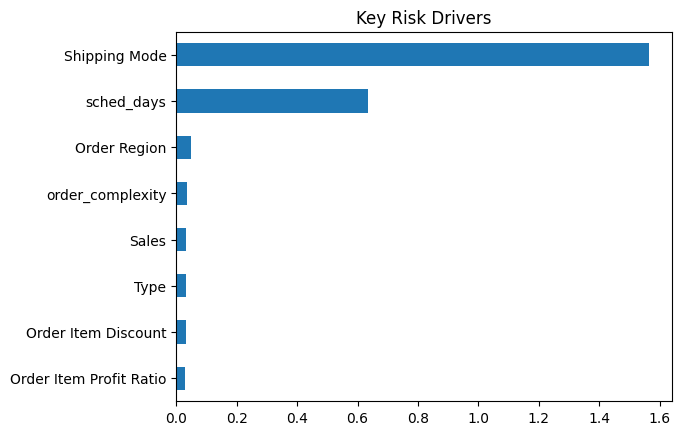

In [46]:
# Step 52: Chart of Key Risk Drivers
drivers.head(8)[::-1].plot(kind='barh')
plt.title('Key Risk Drivers')
plt.show()
# [::-1] -> reverse so the biggest bar is on top

In [47]:
# Step 53: Why is THIS order high risk?
# WHY? The brief asks for an explanation of individual orders.
sample_prob = xgb.predict_proba(sample)[:, 1]
top = sample_prob.argmax()
print('Probability:', round(sample_prob[top], 3))
print(sample.iloc[top][['Shipping Mode', 'Market',
                        'Order Region']])
why = (pd.Series(sv[top], index=names)
         .groupby(original_name).sum())
why.sort_values(key=abs, ascending=False).head(5).round(3)
# Positive number = pushes toward LATE. Negative = pushes toward on time.

Probability: 1.0
Shipping Mode     First Class
Market                 Africa
Order Region     North Africa
Name: 101890, dtype: object


Shipping Mode               7.560
sched_days                  1.553
Order Region                0.160
Order Item Product Price    0.134
shipping_pressure           0.108
dtype: float32

In [48]:
# Step 54: KPI 4: High-Risk Order List
# WHY? The action queue: High Risk orders, riskiest first.
high = df[df['Risk Category'] == 'High Risk']
high = high.sort_values('Late Delivery Probability',
                        ascending=False)
cols = ['Order Ref', 'Shipping Mode', 'Market',
        'Order Region', 'Customer Segment',
        'Sales', 'Late Delivery Probability']
high_list = high[cols]
print(len(high_list))
high_list.head(5)

57801


,Order Ref,Shipping Mode,Market,Order Region,Customer Segment,Sales,Late Delivery Probability
104913,104914,First Class,Pacific Asia,Eastern Asia,Corporate,299.95,0.999962
98558,98559,First Class,Pacific Asia,West Asia,Consumer,299.97,0.999962
57002,57003,First Class,USCA,East of USA,Home Office,119.96,0.999957
77714,77715,First Class,LATAM,Central America,Corporate,124.95,0.999957
51883,51884,First Class,Africa,Southern Africa,Corporate,399.98,0.999955


In [49]:
# Step 55: KPI summary
kpi = {
 'Avg Late Delivery Probability':
     round(df['Late Delivery Probability'].mean(), 3),
 'High Risk orders':
     int((df['Risk Category'] == 'High Risk').sum()),
 'Top Key Risk Driver': drivers.index[0],
 'Model ROC-AUC': round(results['XGBoost']['ROC-AUC'], 3)}
for k, v in kpi.items():
    print(k, ':', v)

Avg Late Delivery Probability : 0.519
High Risk orders : 57801
Top Key Risk Driver : Shipping Mode
Model ROC-AUC : 0.746


In [50]:
# Step 56: Save files for the app
# WHY? The Streamlit app needs: the model, the scaling recipe, scored orders, scores, drivers.
# We save the model as plain JSON text, so it opens on ANY library version.
import os, json, sklearn, xgboost
os.makedirs('deploy', exist_ok=True)
pre_fit = xgb.named_steps['pre']
scaler = pre_fit.named_transformers_['num']
encoder = pre_fit.named_transformers_['cat']
xgb.named_steps['model'].save_model('deploy/xgb_model.json')
prep = {'num_cols': num_cols,
        'num_mean': scaler.mean_.tolist(),
        'num_scale': scaler.scale_.tolist(),
        'cat_cols': cat_cols,
        'cat_values': {c: [str(v) for v in cats]
            for c, cats in zip(cat_cols, encoder.categories_)},
        'reg_rate': reg_rate.to_dict(),
        'global_rate': float(global_rate)}
json.dump(prep, open('deploy/preprocess.json', 'w'))
keep = ['Order Ref', 'Shipping Mode', 'Market',
        'Order Region', 'Customer Segment', 'Type',
        'Department Name', 'Order Item Quantity', 'Sales',
        'Late_delivery_risk', 'Late Delivery Probability',
        'Risk Category']
df[keep].to_csv('deploy/scored_orders.csv.gz',
                index=False, compression='gzip')
json.dump(results, open('deploy/metrics.json', 'w'))
drivers.reset_index().to_csv('deploy/risk_drivers.csv',
    index=False, header=['Feature', 'Importance'])
high_list.to_csv('high_risk_orders.csv', index=False)
print(sorted(os.listdir('deploy')))
# save_model(...json) -> the trained XGBoost saved as text, no version problems
# preprocess.json -> the scaling numbers and category lists, so the app can repeat our preprocessing
# compression='gzip' -> shrinks the CSV (GitHub web upload allows only 25 MB per file)

['metrics.json', 'preprocess.json', 'risk_drivers.csv', 'scored_orders.csv.gz', 'xgb_model.json']


In [51]:
# Step 57: Make requirements.txt
# WHY? Streamlit Cloud installs these libraries for the app.
lines = ['streamlit', 'pandas', 'numpy', 'plotly', 'scipy',
         f'xgboost=={xgboost.__version__}']
with open('deploy/requirements.txt', 'w') as f:
    for line in lines:
        print(line, file=f)
print(open('deploy/requirements.txt').read())
# lines = [...] -> one library name per line (xgboost gets YOUR exact version)
# print(line, file=f) -> write the line into the file; print adds the new line for us

streamlit
pandas
numpy
plotly
scipy
xgboost==3.4.1



In [52]:
# Step 58: Check file sizes (GitHub browser upload: max 25 MB per file)
for f in sorted(os.listdir('deploy')):
    mb = os.path.getsize('deploy/' + f) / 1e6
    print(f, round(mb, 2), 'MB')

metrics.json 0.0 MB
preprocess.json 0.0 MB
requirements.txt 0.0 MB
risk_drivers.csv 0.0 MB
scored_orders.csv.gz 2.08 MB
xgb_model.json 0.99 MB


In [53]:
# Step 59: Download the files to your computer (one by one, no zip)
# high_risk_orders.csv = the High-Risk Order List (KPI 4)
# The other 6 files are for the app. File names must stay EXACTLY the same.
try:
    from google.colab import files
    for name in ['deploy/xgb_model.json', 'deploy/preprocess.json',
                 'deploy/scored_orders.csv.gz', 'deploy/metrics.json',
                 'deploy/risk_drivers.csv', 'deploy/requirements.txt',
                 'high_risk_orders.csv']:
        files.download(name)
except ImportError:
    print('Not in Colab: files are saved in the deploy folder.')
# files.download -> your browser downloads the file
# If Chrome asks to allow multiple downloads, click Allow.

Not in Colab: files are saved in the deploy folder.
